# Módulo 3: Extracción de Características, Análisis de Textura y Dinámica Temporal

**Objetivo.** Extraer métricas morfológicas y de textura de la ROI segmentada y procesar la totalidad del video para cuantificar parámetros fisiológicos del reflejo fotomotor.

**Datos.** Se utiliza el mismo frame y la misma ROI que en los módulos anteriores. La segmentación de la pupila corresponde al procedimiento elegido en el Módulo 2 (watershed con marcadores robustos, cierre y envolvente convexa), implementado en `src/segmentacion.py`.

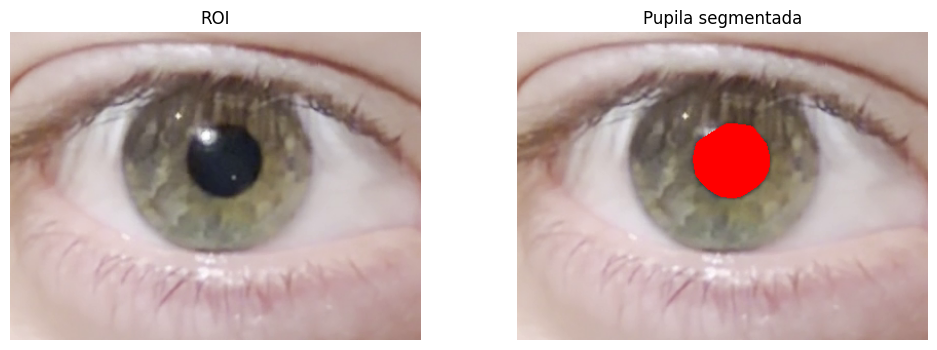

In [10]:
import sys
sys.path.append("..")     # para encontrar config.py y la carpeta src

import cv2
import numpy as np
import matplotlib.pyplot as plt
from config import VIDEO_PATH
from src.segmentacion import segmentar_pupila


# Mismo frame y ROI que en los módulos anteriores
FRAME_IDX = 778
x, y, w, h = 300, 950, 400, 300

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = frame_rgb[y:y+h, x:x+w]
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

# Máscara de la pupila con el método del Módulo 2
mascara = segmentar_pupila(roi)

superpuesta = roi.copy()
superpuesta[mascara == 255] = [255, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(roi)
axes[0].set_title("ROI")
axes[1].imshow(superpuesta)
axes[1].set_title("Pupila segmentada")
for ax in axes:
    ax.axis("off")
plt.show()

## 1. Descriptores Morfométricos y de Textura en el Frame Segmentado

### Descriptores morfométricos

A partir de la máscara binaria de la pupila se calculan:
- Área (A): cantidad de píxeles de la región.
- Perímetro (P): longitud del contorno de la región.
- Centroide $(X_c, Y_c)$: promedio de las coordenadas de los píxeles de la región.
- Circularidad: $C = \dfrac{4\pi A}{P^2}$. Vale 1 para un círculo perfecto y disminuye cuanto más irregular o alargada es la forma.
- Excentricidad: se ajusta a la región una elipse con los mismos momentos de segundo orden y se calcula la relación entre la distancia focal y su eje mayor. Vale 0 para un círculo y tiende a 1 para una forma alargada.
- Diámetro equivalente: diámetro de un círculo con la misma área que la región, $D = \sqrt{4A/\pi}$.

Área:                  4224 px
Perímetro:             241.0 px
Centroide (Xc, Yc):    (208.4, 124.7) px
Circularidad:          0.914
Excentricidad:         0.321
Diámetro equivalente:  73.3 px
Ejes de la elipse:     75.4 × 71.4 px


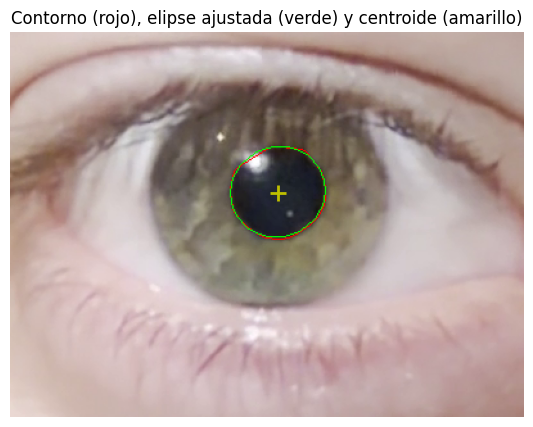

In [ ]:
from skimage.measure import regionprops, label

# Propiedades de la región blanca de la máscara
# label numera las regiones conectadas; regionprops calcula las medidas de cada una. Como hay una sola (la pupila), tomamos [0]
props = regionprops(label(mascara > 0))[0]

area = props.area
perimetro = props.perimeter
yc, xc = props.centroid                 
circularidad = 4 * np.pi * area / perimetro ** 2
excentricidad = props.eccentricity
diametro_eq = props.equivalent_diameter_area

print(f"Área:                  {area:.0f} px")
print(f"Perímetro:             {perimetro:.1f} px")
print(f"Centroide (Xc, Yc):    ({xc:.1f}, {yc:.1f}) px")
print(f"Circularidad:          {circularidad:.3f}")
print(f"Excentricidad:         {excentricidad:.3f}")
print(f"Diámetro equivalente:  {diametro_eq:.1f} px")
print(f"Ejes de la elipse:     {props.axis_major_length:.1f} × {props.axis_minor_length:.1f} px")


# Visualización: contorno, centroide y elipse ajustada
vis = roi.copy()
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(vis, contornos, -1, (255, 0, 0), 1)

# Elipse con los mismos momentos que la región
# (OpenCV pide el ángulo en grados y los semiejes)
angulo = -np.degrees(props.orientation) + 90
cv2.ellipse(vis, (int(xc), int(yc)),
            (int(props.axis_major_length / 2), int(props.axis_minor_length / 2)),
            angulo, 0, 360, (0, 255, 0), 1)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.plot(xc, yc, "y+", markersize=12, mew=2)
plt.title("Contorno (rojo), elipse ajustada (verde) y centroide (amarillo)")
plt.axis("off")
plt.show()

La pupila segmentada en el frame 778 tiene un área de 4224 px y un perímetro de 241 px, con su centroide ubicado en (208,4; 124,7) px dentro de la ROI. Su diámetro equivalente, es decir, el de un círculo con la misma área, es de 73,3 px.

La circularidad obtenida es de 0,914, cercana a 1, lo que indica una forma muy próxima a un círculo. Parte de la diferencia respecto del valor ideal se debe a que el contorno está formado por píxeles discretos: el perímetro de una figura "escalonada" resulta algo mayor que el de un círculo continuo, lo que reduce la circularidad aunque la forma sea redonda. También contribuye el tramo recto que introduce la envolvente convexa en la zona del reflejo corneal.

La excentricidad es de 0,321, y la elipse ajustada tiene ejes de 75,4 y 71,4 px, por lo que el eje menor es aproximadamente un 95 % del mayor. Aunque el valor de excentricidad pueda parecer alto, esta medida es muy sensible cerca de la forma circular: una diferencia de solo el 5 % entre los ejes ya produce una excentricidad de alrededor de 0,3. La leve elongación puede deberse a que la cámara no estaba perfectamente frontal al ojo, lo que hace que la pupila se proyecte como una elipse, o a pequeñas irregularidades de la segmentación.

En conclusión, ambos descriptores indican que la pupila presenta una forma regular, sin deformaciones significativas.

### Textura de primer orden

La textura de primer orden describe la distribución de intensidades de una región a partir de su histograma, sin considerar la posición de los píxeles. Se calculan cuatro estadísticos:
- **Media:** intensidad promedio de la región.
- **Desvío estándar:** dispersión de las intensidades alrededor de la media; cuanto mayor, más contraste interno.
- **Entropía:** $H = -\sum_i p_i \log_2 p_i$, donde $p_i$ es la probabilidad de cada nivel de gris. Mide la aleatoriedad o complejidad de la distribución: es baja si predominan pocos niveles y alta si las intensidades están repartidas en muchos niveles.
- **Asimetría (skewness):** indica si el histograma tiene una cola hacia valores altos (positiva) o bajos (negativa).

Se calculan por separado en los canales R, G y B, sobre dos regiones: la **pupila**, obtenida con la segmentación del Módulo 2, y el **iris**, definido como el anillo entre el borde de la pupila y el borde externo del iris. El borde del iris se detecta con la transformada de Hough para círculos. Para la entropía, cada canal se cuantiza a 64 niveles de gris.

Iris: centro (202, 124) px, radio 94 px


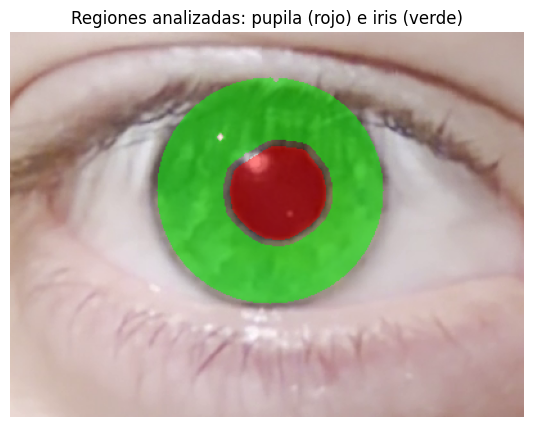

In [ ]:
# 1) Borde externo del iris con la transformada de Hough
# Radio aproximado de la pupila (a partir de su área)
radio_pupila = np.sqrt(area / np.pi)

# Suavizamos con mediana para que la textura del iris no genere
# círculos falsos
gris_suave = cv2.medianBlur(roi_gris, 7)

# HoughCircles busca círculos en la imagen:
circulos = cv2.HoughCircles(
    gris_suave, cv2.HOUGH_GRADIENT, dp=1, minDist=1000,
    param1=60, param2=20,
    minRadius=int(2 * radio_pupila), maxRadius=int(4 * radio_pupila)
)
x_iris, y_iris, radio_iris = circulos[0][0]
print(f"Iris: centro ({x_iris:.0f}, {y_iris:.0f}) px, radio {radio_iris:.0f} px")


# 2) Máscara del iris: anillo entre la pupila y el borde del iris
# Círculo del iris un 5 % más chico, para no incluir la esclerótica
disco_iris = np.zeros_like(roi_gris)
cv2.circle(disco_iris, (int(x_iris), int(y_iris)), int(0.95 * radio_iris), 255, -1)

# Pupila agrandada unos píxeles, para no incluir su borde
ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
pupila_agrandada = cv2.dilate(mascara, ee)

# Iris = disco del iris, sin la pupila y sin reflejos (píxeles muy claros)
mascara_iris = (disco_iris > 0) & (pupila_agrandada == 0) & (roi_gris < 170)
mascara_pupila = mascara > 0


# 3) Visualización
vis = roi.copy()
vis[mascara_iris] = (0.5 * vis[mascara_iris] + [0, 127, 0]).astype(np.uint8)
vis[mascara_pupila] = (0.5 * vis[mascara_pupila] + [127, 0, 0]).astype(np.uint8)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.title("Regiones analizadas: pupila (rojo) e iris (verde)")
plt.axis("off")
plt.show()

Media  Desvío  Entropía (bits)  Asimetría
Región Canal                                            
Pupila R       46.12   36.05             3.66       3.75
       G       46.30   35.51             3.55       3.94
       B       52.30   35.20             3.78       3.85
Iris   R      120.35   24.10             4.53       0.05
       G      109.62   27.19             4.67      -0.04
       B       95.65   24.52             4.58       0.13

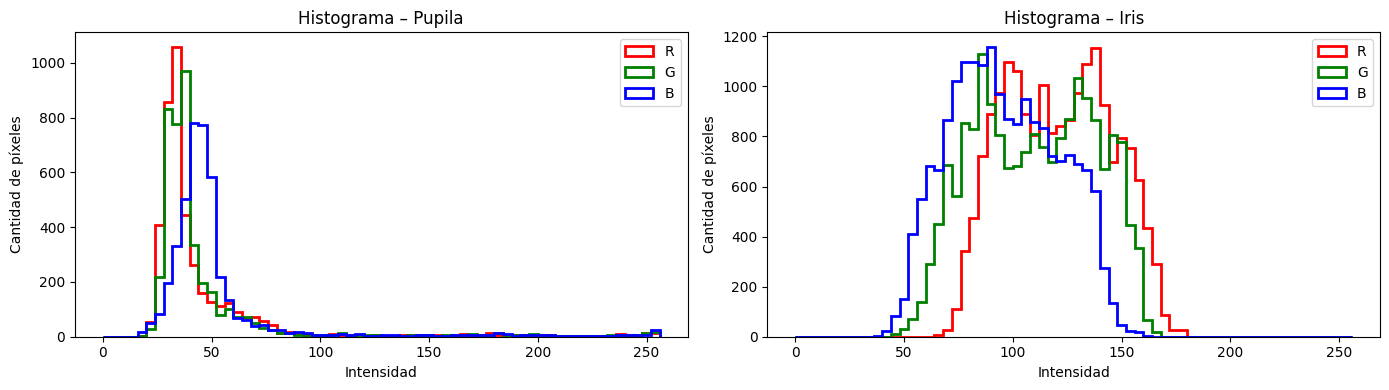

In [ ]:
import pandas as pd
from scipy.stats import skew


# Entropía de un conjunto de valores, cuantizados a 64 niveles
def entropia(valores, niveles=64):
    cuantizados = valores // (256 // niveles)               
    conteo = np.bincount(cuantizados, minlength=niveles)
    p = conteo / conteo.sum() # probabilidades
    p = p[p > 0] # log(0) no está definido
    return -np.sum(p * np.log2(p))

# Estadísticos por región y por canal
regiones = {"Pupila": mascara_pupila, "Iris": mascara_iris}
canales = {"R": 0, "G": 1, "B": 2}

filas = []
for nombre_region, region in regiones.items():
    for nombre_canal, c in canales.items():
        # Valores del canal solo dentro de la región (lista 1D de píxeles)
        valores = roi[:, :, c][region]
        filas.append({
            "Región": nombre_region,
            "Canal": nombre_canal,
            "Media": valores.mean(),
            "Desvío": valores.std(),
            "Entropía (bits)": entropia(valores),
            "Asimetría": skew(valores.astype(float)),
        })

df_primer_orden = pd.DataFrame(filas).set_index(["Región", "Canal"]).round(2)
display(df_primer_orden)


# Histogramas del iris en cada canal
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre_region, region) in zip(axes, regiones.items()):
    for nombre_canal, c in canales.items():
        ax.hist(roi[:, :, c][region], bins=64, range=(0, 256),
                histtype="step", linewidth=2,
                color={"R": "red", "G": "green", "B": "blue"}[nombre_canal],
                label=nombre_canal)
    ax.set_title(f"Histograma – {nombre_region}")
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Cantidad de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()

Para el análisis de textura se excluyeron de ambas regiones los píxeles correspondientes a reflejos corneales (intensidad en escala de grises mayor o igual a 170), ya que no representan tejido sino luz reflejada. Al excluirlos, el desvío estándar de la pupila se redujo de aproximadamente 36 a 19 niveles de gris.

Pupila: Presenta intensidades medias bajas en los tres canales (41 en R, 41 en G y 47 en B), con un histograma concentrado en un pico angosto entre 25 y 55. La entropía es la más baja de las dos regiones (entre 3,3 y 3,6 bits de un máximo de 6 bits para 64 niveles), lo que indica una región oscura y relativamente uniforme. Sin embargo, la asimetría sigue siendo alta y positiva (entre 3,1 y 3,6) lo cual se ve en el histograma que conserva una cola hacia intensidades mayores. Esta cola corresponde a los píxeles del borde de la pupila, que mezclan intensidades de la pupila y del iris, y al halo de los reflejos corneales, cuyos valores intermedios no se eliminan con el umbral utilizado. El valor algo más alto del canal B es coherente con el tono levemente azulado de las zonas oscuras de la imagen.

Iris: Presenta intensidades medias mayores, con R > G > B (120, 110 y 96), lo que corresponde al tono verde-amarronado de un iris claro. Su desvío estándar (entre 24 y 27) y su entropía (entre 4,5 y 4,7 bits) son mayores que los de la pupila, lo que refleja la mayor variabilidad de intensidades del estroma iridiano. La asimetría es prácticamente nula (entre −0,04 y 0,13), es decir, el histograma es aproximadamente simétrico. En los tres canales se observan dos picos, uno en intensidades bajas y otro en intensidades altas, lo que sugiere la presencia de dos tipos de zonas en el iris: regiones más oscuras y más claras del estroma, posiblemente acentuadas por la sombra del párpado sobre la parte superior.

Entre los canales del iris, el G presenta el mayor desvío (27,2) y la mayor entropía (4,67 bits), por lo que es el que muestra mayor variabilidad de intensidades. Igualmente, las diferencias entre canales son pequeñas, por lo que la comparación se retoma con los descriptores de segundo orden, que también consideran la disposición espacial de los píxeles.

### Textura de segundo orden (GLCM)

La Matriz de Co-ocurrencia de Niveles de Gris (GLCM) registra con qué frecuencia aparecen pares de píxeles con determinados niveles de gris, separados por una distancia y una dirección dadas. A diferencia de los estadísticos de primer orden, considera la disposición espacial de las intensidades. De ella se extraen cuatro atributos:
- Contraste: diferencia de intensidad entre píxeles vecinos. Es alto cuando hay cambios bruscos entre vecinos.
- Homogeneidad: cercanía de los valores a la diagonal de la matriz. Es alta cuando los vecinos tienen intensidades parecidas.
- Energía: uniformidad de la matriz. Es alta cuando se repiten pocos pares de niveles, es decir, en texturas ordenadas o uniformes.
- Correlación: dependencia lineal entre el nivel de un píxel y el de su vecino.

Cada canal (R, G, B) se cuantiza a 64 niveles y la GLCM se calcula con distancia de 1 píxel en cuatro direcciones (0°, 45°, 90° y 135°), promediando los atributos. Como el iris tiene forma de anillo, se analizan cuatro ventanas de 32 × 32 px ubicadas dentro del iris (arriba, abajo, izquierda y derecha de la pupila) y se promedian sus resultados.

Contraste        Homogeneidad        Energía        Correlación       
           mean    std         mean    std    mean    std        mean    std
Canal                                                                       
R         1.339  0.572        0.666  0.058   0.174  0.025       0.942  0.025
G         1.338  0.544        0.669  0.055   0.171  0.022       0.950  0.020
B         1.342  0.547        0.660  0.050   0.165  0.014       0.951  0.024

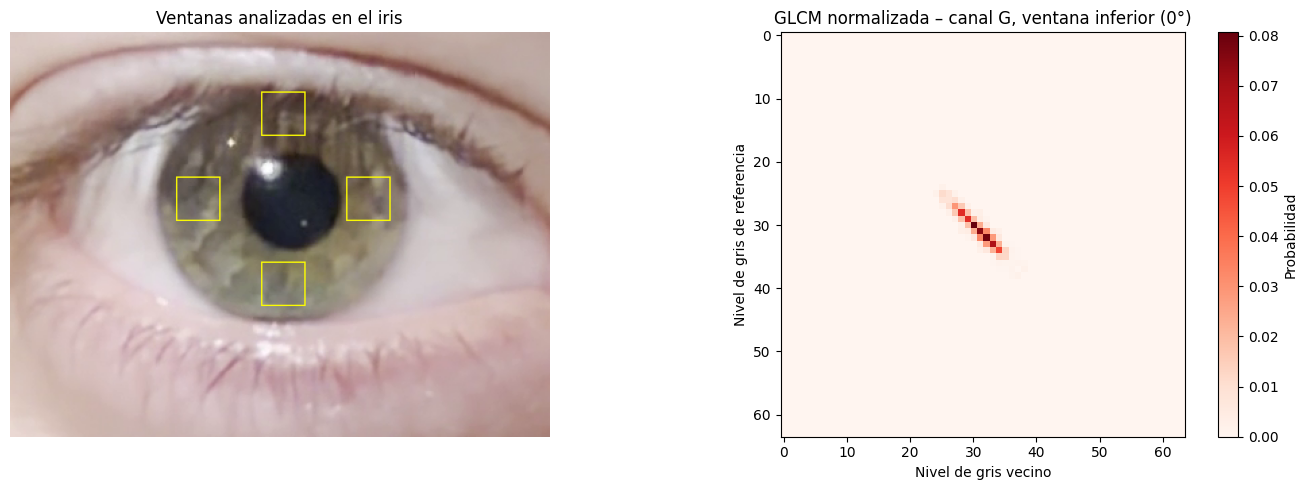

,Contraste,Homogeneidad,Energía,Correlación
Ventana,,,,
Arriba,2.104,0.594,0.148,0.933
Abajo,0.824,0.727,0.200,0.935
Izquierda,1.156,0.677,0.164,0.976
Derecha,1.267,0.679,0.171,0.954


In [15]:
from skimage.feature import graycomatrix, graycoprops


# Reducción de niveles de gris
NIVELES = 64

def reducir_niveles(imagen, n_grey):
    return np.floor_divide(imagen, 256 // n_grey)


# Ubicación de las 4 ventanas dentro del iris
TAM = 32 # tamaño de cada ventana (px)

# Las centramos a mitad de camino entre el borde de la pupila y el borde del iris, para que queden enteras dentro del anillo
r_medio = (radio_pupila + 0.95 * radio_iris) / 2

centros = {
    "Arriba":    (x_iris, y_iris - r_medio),
    "Abajo":     (x_iris, y_iris + r_medio),
    "Izquierda": (x_iris - r_medio, y_iris),
    "Derecha":   (x_iris + r_medio, y_iris),
}

# Esquina superior izquierda de cada ventana
ventanas = {nombre: (int(cx - TAM / 2), int(cy - TAM / 2))
            for nombre, (cx, cy) in centros.items()}

# GLCM y atributos por canal y por ventana
distancias = [1]
angulos = [0, np.pi/4, np.pi/2, 3*np.pi/4]       # 0°, 45°, 90°, 135°
atributos = ["contrast", "homogeneity", "energy", "correlation"]
nombres_atrib = ["Contraste", "Homogeneidad", "Energía", "Correlación"]

filas = []
for nombre_canal, c in canales.items():
    canal_red = reducir_niveles(roi[:, :, c], NIVELES)

    for nombre_ventana, (x0, y0) in ventanas.items():
        ventana = canal_red[y0:y0+TAM, x0:x0+TAM]

        glcm = graycomatrix(ventana, distances=distancias, angles=angulos,
                            levels=NIVELES, symmetric=True, normed=True)

        fila = {"Canal": nombre_canal, "Ventana": nombre_ventana}
        for atrib, nombre in zip(atributos, nombres_atrib):
            # graycoprops devuelve un valor por ángulo; los promediamos
            fila[nombre] = graycoprops(glcm, atrib).mean()
        filas.append(fila)

df_glcm = pd.DataFrame(filas)

# Resultado por canal: promedio y desvío de las 4 ventanas
resumen_glcm = df_glcm.groupby("Canal")[nombres_atrib].agg(["mean", "std"]).round(3)
display(resumen_glcm.loc[["R", "G", "B"]])


# Visualización: ventanas sobre la ROI y GLCM del canal G (ventana inferior)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vis = roi.copy()
for nombre_ventana, (x0, y0) in ventanas.items():
    cv2.rectangle(vis, (x0, y0), (x0 + TAM, y0 + TAM), (255, 255, 0), 1)
axes[0].imshow(vis)
axes[0].set_title("Ventanas analizadas en el iris")
axes[0].axis("off")

x0, y0 = ventanas["Abajo"]
ventana_g = reducir_niveles(roi[:, :, 1], NIVELES)[y0:y0+TAM, x0:x0+TAM]
glcm_g = graycomatrix(ventana_g, [1], [0], levels=NIVELES, symmetric=True, normed=True)
im = axes[1].imshow(glcm_g[:, :, 0, 0], cmap="Reds")
plt.colorbar(im, ax=axes[1], label="Probabilidad")
axes[1].set_title("GLCM normalizada – canal G, ventana inferior (0°)")
axes[1].set_xlabel("Nivel de gris vecino")
axes[1].set_ylabel("Nivel de gris de referencia")

plt.tight_layout()
plt.show()

display(df_glcm[df_glcm["Canal"] == "G"].set_index("Ventana")[nombres_atrib].round(3))

Los atributos de la GLCM resultan prácticamente iguales en los tres canales: el contraste es de 1,34 en R, G y B, la homogeneidad está entre 0,660 y 0,669, la energía entre 0,165 y 0,174, y la correlación entre 0,942 y 0,951. Las diferencias entre canales son mucho menores que la variación entre las cuatro ventanas de un mismo canal: por ejemplo, el desvío del contraste entre ventanas es de aproximadamente 0,55, mientras que la diferencia entre canales es menor a 0,01. Es decir, la textura cambia más según la zona del iris que se analiza que según el canal de color.

La GLCM del canal G en la ventana inferior muestra los valores concentrados en una franja angosta alrededor de la diagonal. Esto indica que los píxeles vecinos tienen casi siempre niveles de gris muy parecidos, lo que es coherente con la alta homogeneidad y la alta correlación (cercana a 0,95) obtenidas. A la distancia de 1 píxel, la textura del iris resulta suave: los cambios de intensidad son graduales. Además, los valores ocupan solo un rango reducido de los 64 niveles (aproximadamente entre 25 y 37 en esa ventana), lo que muestra que el contraste dentro de cada zona del iris es bajo.

Respecto de qué canal aporta mayor riqueza textural del estroma iridiano, ningún canal se destaca de forma significativa. En la textura de primer orden, el canal G presentó el mayor desvío y la mayor entropía, y en la de segundo orden el canal B presenta una energía y una homogeneidad levemente menores; pero en ambos casos las diferencias son pequeñas y están dentro de la variabilidad entre ventanas.

Al comparar las ventanas en el canal G, la ventana superior presenta el mayor contraste (2,10) y la menor homogeneidad (0,594) y energía (0,148), mientras que la inferior presenta el menor contraste (0,82) y la mayor homogeneidad (0,727) y energía (0,200). Las ventanas laterales tienen valores intermedios. La mayor heterogeneidad de la zona superior puede atribuirse a la sombra del párpado y de las pestañas sobre el iris, que agregan cambios de intensidad que no pertenecen al estroma. Esto muestra que la textura medida depende de la región analizada y que, para caracterizar el iris, conviene considerar varias zonas o excluir las afectadas por el párpado.

## 2. Procesamiento en Video y Curva Temporal Fisiológica

Para procesar los videos completos se armó un pipeline en `src/pipeline.py`, que es el mismo que ejecuta `main.py` en la entrega final. Los pasos son:

1. **Localización automática del ojo:** en 9 frames repartidos en el video se buscan regiones oscuras y redondeadas rodeadas de algo más claro (detector de blobs LoG) y se elige la posición que más se repite. Así la ROI no depende de coordenadas fijas y el pipeline funciona con un video nuevo.
2. **Seguimiento:** la ROI (del mismo tamaño relativo que la de los módulos anteriores) se recentra en cada frame sobre la pupila, para acompañar los movimientos de la cabeza.
3. **Segmentación de la pupila** en cada frame y cálculo del diámetro y el área.
4. **Limpieza de artefactos** (parpadeos, movimientos, transiciones de la cámara) e interpolación.
5. **Detección del estímulo** y cálculo de los parámetros fisiológicos.

### Segmentación para video

El watershed elegido en el Módulo 2 funciona muy bien en el frame de trabajo, pero usa umbrales fijos de intensidad (pupila < 40, fondo > 70). A lo largo de los videos la cámara del celular reajusta la exposición automáticamente después de cada cambio de luz: en los registros B, al apagar la luz, la imagen se oscurece y el iris queda casi tan oscuro como la pupila. Con umbrales fijos, la inundación se extiende hacia el iris y la sombra del párpado.

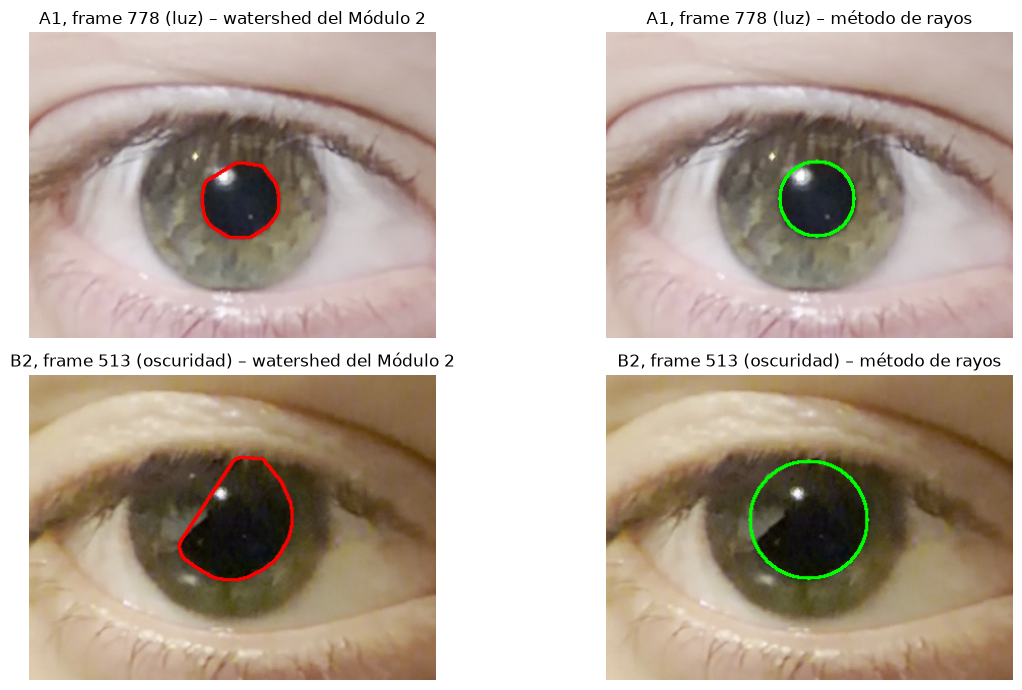

In [ ]:
from config import DATA_DIR
from src.pipeline import localizar_ojo, recortar_roi, analizar_video, graficar
from src.pupila_video import segmentar_pupila_video

def leer_frame_exacto(video, idx):
    # Lee el frame número idx recorriendo el video desde el principio. Con frame rate variable,
    # cap.set(CAP_PROP_POS_FRAMES, idx) no cae exactamente en ese frame (ver la validación más abajo).
    cap = cv2.VideoCapture(str(video))
    for _ in range(idx):
        cap.grab()
    ok, f = cap.read()
    cap.release()
    return f

def roi_de_video(video, idx):
    cx, cy = localizar_ojo(video)
    f = leer_frame_exacto(video, idx)
    roi_bgr, _, _ = recortar_roi(f, cx, cy)
    return cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)

def contorno_sobre(roi_rgb, m, color):
    vis = roi_rgb.copy()
    c, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(vis, c, -1, color, 2)
    return vis

ejemplos = [("A1.mp4", 778, "A1, frame 778 (luz)"), ("B2.mp4", 513, "B2, frame 513 (oscuridad)")]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for fila, (video, idx, titulo) in enumerate(ejemplos):
    r = roi_de_video(DATA_DIR / video, idx)
    m_ws = segmentar_pupila(r)
    m_rayos, _ = segmentar_pupila_video(r)
    axes[fila, 0].imshow(contorno_sobre(r, m_ws, (255, 0, 0)))
    axes[fila, 0].set_title(f"{titulo} – watershed del Módulo 2")
    axes[fila, 1].imshow(contorno_sobre(r, m_rayos, (0, 255, 0)))
    axes[fila, 1].set_title(f"{titulo} – método de rayos")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Por eso, para el video se implementó en `src/pupila_video.py` un método adaptativo que no depende de umbrales fijos:

1. **Reflejos:** se detectan los puntos mucho más claros que su entorno (diferencia con un filtro de mediana) y se rellenan por *inpainting*, para que no corten el borde de la pupila.
2. **Centro inicial:** se toman los píxeles cercanos al mínimo de intensidad de la ROI y, con la transformada de distancia, se elige el centro del disco más grande que entra en esa región oscura. Si en el frame anterior había pupila, se busca cerca de esa posición.
3. **Umbral adaptativo:** se estiman en cada frame el nivel de la pupila (mediana del disco central) y el del iris (corona alrededor), y el umbral se ubica al 30 % entre ambos. La fracción se calibró con los frames anotados a mano.
4. **Rayos ("starburst"):** desde el centro se trazan 48 rayos y en cada uno se busca el primer punto donde la intensidad supera el umbral, es decir, el borde pupilar. No se trazan rayos en un sector de 150° hacia arriba, donde el borde suele quedar tapado por el párpado, las pestañas o su sombra.
5. **Ajuste robusto de un círculo** a esos puntos (mínimos cuadrados), descartando de forma iterativa los puntos alejados (más de 2,5 MAD), que corresponden a rayos que se escaparon por las pestañas o un reflejo. Si menos de la mitad de los rayos coincide con el círculo, o no hay contraste entre pupila e iris, el frame se marca como inválido (por ejemplo, durante un parpadeo).

El diámetro se obtiene directamente del radio del círculo ajustado, con precisión subpíxel.

In [ ]:
# Validación de la segmentación frame a frame contra las anotaciones manuales
# (misma ROI fija que en los módulos anteriores, para que coincida con las anotaciones)
FRAMES_ANOTADOS = [150, 400, 600, 778, 880]

def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum())

filas = []
for idx in FRAMES_ANOTADOS:
    cap = cv2.VideoCapture(str(DATA_DIR / "A1.mp4"))
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, f = cap.read()
    cap.release()
    r = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)[y:y+h, x:x+w]
    ref = cv2.imread(f"../anotaciones/frame_{idx}.png", cv2.IMREAD_GRAYSCALE) > 0
    d_ref = np.sqrt(4 * ref.sum() / np.pi)

    m_ws = segmentar_pupila(r) > 0
    m_ray = segmentar_pupila_video(r)[0] > 0
    filas.append({"Frame": idx, "D manual (px)": d_ref,
                  "D watershed (px)": np.sqrt(4 * m_ws.sum() / np.pi), "Dice watershed": dice(m_ws, ref),
                  "D rayos (px)": np.sqrt(4 * m_ray.sum() / np.pi), "Dice rayos": dice(m_ray, ref)})

df_val = pd.DataFrame(filas).set_index("Frame")
display(df_val.round(3))

for metodo in ["watershed", "rayos"]:
    err = df_val[f"D {metodo} (px)"] - df_val["D manual (px)"]
    print(f"{metodo:10s}  MAE = {err.abs().mean():.2f} px   RMSE = {np.sqrt((err ** 2).mean()):.2f} px   "
          f"Dice medio = {df_val[f'Dice {metodo}'].mean():.3f}")

,D manual (px),D watershed (px),Dice watershed,D rayos (px),Dice rayos
Frame,,,,,
150,55.221,56.532,0.962,55.886,0.943
400,75.323,76.937,0.971,77.989,0.947
600,66.306,68.097,0.967,65.882,0.956
778,71.703,73.388,0.955,71.836,0.970
880,85.764,87.251,0.962,87.963,0.958


watershed   MAE = 1.58 px   RMSE = 1.59 px   Dice medio = 0.963
rayos       MAE = 1.22 px   RMSE = 1.59 px   Dice medio = 0.955


En el frame de trabajo con luz (A1) ambos métodos encuentran la misma pupila. En el frame oscuro de B2, en cambio, el watershed se extiende hacia la sombra del párpado y produce una forma de "gota" que sobreestima la pupila, mientras que el método de rayos ajusta un círculo al borde visible.

Sobre los 5 frames anotados, los dos métodos tienen un error similar: el watershed del Módulo 2 tiene un error absoluto medio (MAE) en el diámetro de 1,58 px (RMSE 1,59 px, Dice 0,963) y el método de rayos de 1,22 px (RMSE 1,59 px, Dice 0,955). Es decir, en condiciones favorables ambos miden la pupila con un error de 1 a 2 px (alrededor del 2 % del diámetro), pero el método de rayos además se mantiene estable cuando cambia la exposición, por lo que es el que se usa en el pipeline.

### Curva temporal del diámetro pupilar

Se procesan todos los registros de la carpeta `data/` (2 registros A y 4 registros B). Para cada uno, `analizar_video` guarda en `outputs/` la curva frame a frame (`<video>_curva.csv`), los parámetros (`<video>_parametros.csv`) y un gráfico. El tiempo de cada frame se toma de su marca temporal, porque los videos del celular tienen frame rate variable (entre 24 y 30 fps).

In [ ]:
from pathlib import Path
CARPETA_SALIDA = Path("..") / "outputs"

videos = sorted(DATA_DIR.glob("*.mp4"))
curvas, parametros = {}, []
for video in videos:
    df_v, p = analizar_video(video, CARPETA_SALIDA, progreso=False)
    curvas[video.stem] = df_v
    parametros.append(p)
    print(f"{video.name}: {len(df_v)} frames, registro {p['tipo_registro']}, "
          f"{p['frames_invalidos_pct']:.1f} % de frames descartados")
df_param = pd.DataFrame(parametros).set_index("video")

A1.mp4: 909 frames, registro A, 0.4 % de frames descartados
A2.mp4: 945 frames, registro A, 5.0 % de frames descartados
B1.mp4: 697 frames, registro B, 3.9 % de frames descartados
B2.mp4: 782 frames, registro B, 1.5 % de frames descartados
B3.mp4: 797 frames, registro B, 3.0 % de frames descartados
B4.mp4: 753 frames, registro B, 4.2 % de frames descartados


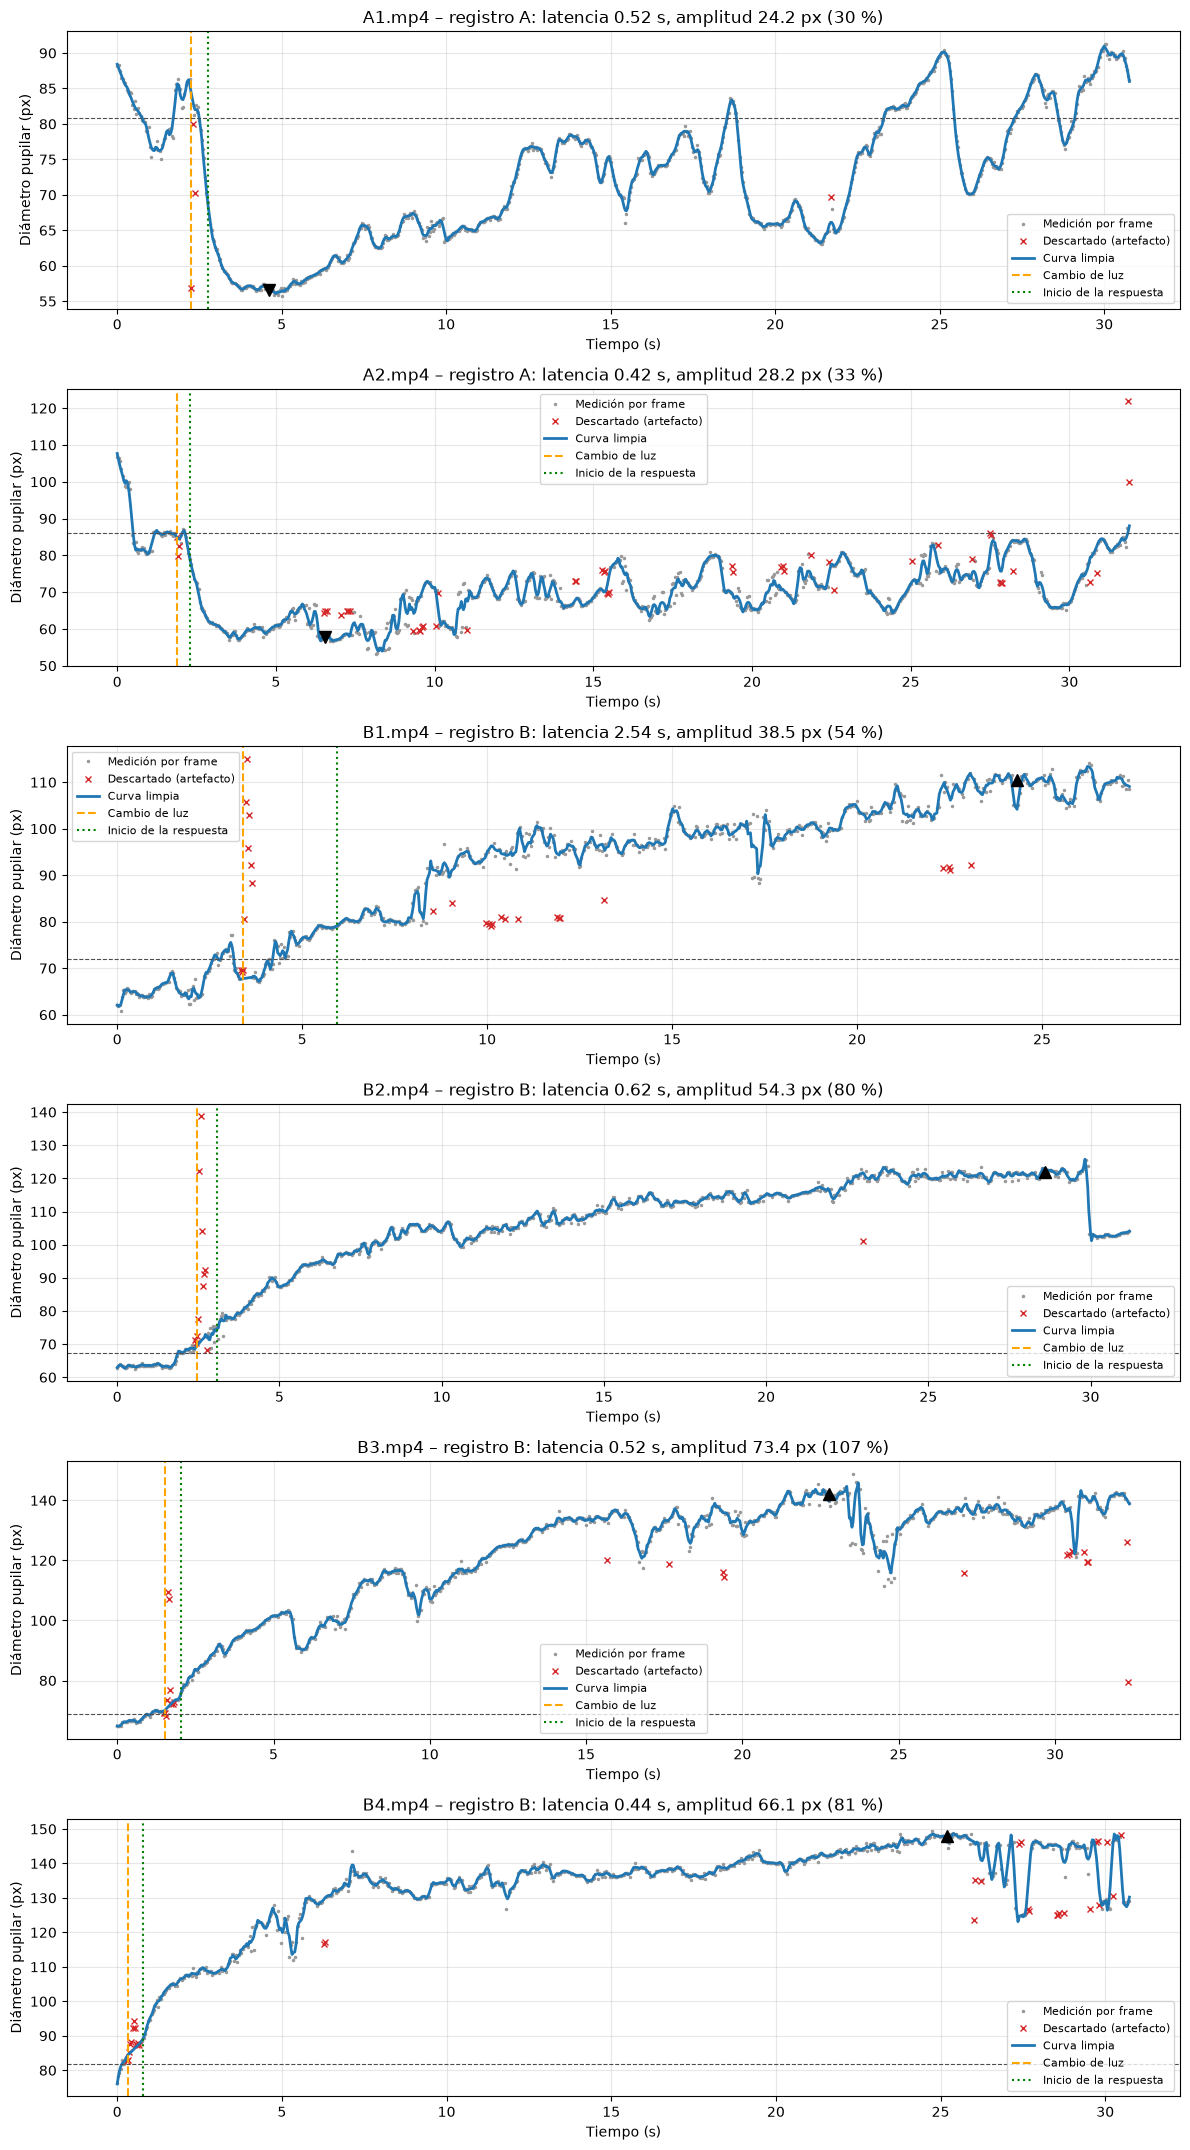

In [ ]:
# Curva D(t) de cada registro, con el estímulo, el inicio de la respuesta y el extremo marcados
nombres = list(curvas)
fig, axes = plt.subplots(len(nombres), 1, figsize=(12, 3.6 * len(nombres)))
for ax, nombre in zip(np.atleast_1d(axes), nombres):
    graficar(curvas[nombre], {**df_param.loc[f"{nombre}.mp4"].to_dict(), "video": f"{nombre}.mp4"}, ax=ax)
plt.tight_layout()
plt.show()

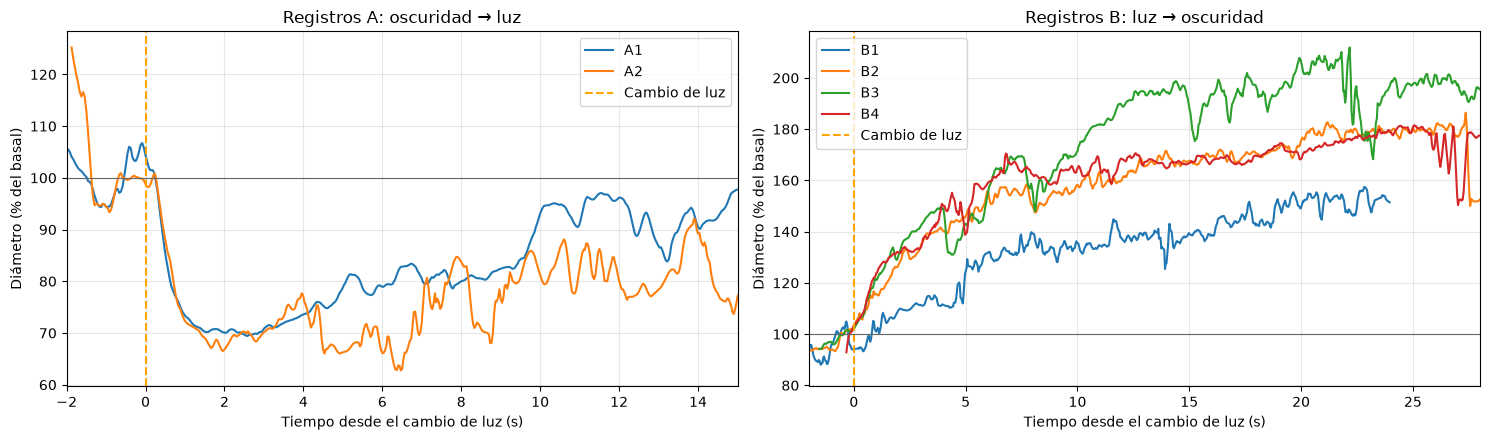

In [ ]:
# Comparación entre registros: diámetro relativo al basal, alineado en el estímulo
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for tipo, ax in zip(["A", "B"], axes):
    for nombre, df_v in curvas.items():
        p = df_param.loc[f"{nombre}.mp4"]
        if p["tipo_registro"] != tipo:
            continue
        t_rel = df_v["tiempo_s"] - p["t_estimulo_s"]
        ax.plot(t_rel, 100 * df_v["diametro_px_limpio"] / p["diametro_basal_px"], label=nombre)
    ax.axvline(0, color="orange", ls="--", label="Cambio de luz")
    ax.axhline(100, color="0.4", lw=0.8)
    ax.set_xlim(-2, 15 if tipo == "A" else 28)
    ax.set_xlabel("Tiempo desde el cambio de luz (s)")
    ax.set_ylabel("Diámetro (% del basal)")
    ax.set_title("Registros A: oscuridad → luz" if tipo == "A" else "Registros B: luz → oscuridad")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Registros A (contracción).** Antes del estímulo, con poca luz, la pupila tiene un diámetro de 81 a 86 px. Al encender la luz se contrae rápidamente: en aproximadamente 1,5 a 2 s llega a cerca del 70 % de su diámetro basal (unos 57 px). Los dos registros se superponen casi exactamente durante la constricción, lo que muestra que la respuesta es muy reproducible. Después del mínimo, la pupila se redilata parcialmente aunque la luz siga encendida, hasta un 80 a 95 % del basal: es el **escape pupilar**, la adaptación del reflejo ante un estímulo sostenido. En ese tramo aparecen oscilaciones de varios píxeles, que corresponden a la inestabilidad normal de la pupila (*hippus*) y a pequeños cambios en la iluminación al mover la linterna. En A2, los valores altos del primer medio segundo (de 108 a 81 px) no son fisiológicos: el brillo del video no cambia y el centro detectado salta entre dos posiciones, por lo que corresponden a errores de segmentación en los primeros frames, mientras el seguimiento todavía no se estabilizó. No afectan a los parámetros, porque el diámetro basal se mide en el segundo previo al estímulo (de 0,9 a 1,9 s).

**Registros B (redilatación).** Con la pupila contraída por la luz, el diámetro basal es de 67 a 82 px. Al apagar la luz, la pupila empieza a agrandarse, pero mucho más lentamente que en la contracción: no alcanza una meseta clara en los 25 a 30 s del registro y sigue creciendo hasta un 150 a 200 % de su diámetro basal. La curva tiene una fase inicial más rápida (los primeros 5 a 8 s) y después un crecimiento lento. B2, B3 y B4 se comportan de forma parecida; B1 se dilata menos y más despacio, y su tramo previo al estímulo no es estable (el diámetro ya venía aumentando), lo que sugiere que la luz no estaba fija antes de apagarla. En B2, la caída brusca de los últimos segundos (de unos 122 a 103 px) no es fisiológica: el brillo del video no cambia y el centro detectado se desplaza hacia abajo, lo que indica que el párpado superior bajó y tapó parte de la pupila. No afecta a los parámetros porque el máximo se alcanza antes.

La comparación confirma lo que plantea el protocolo: la **constricción es rápida** y la **redilatación es lenta**.

### Parámetros fisiológicos

Se calculan sobre la curva limpia del diámetro (`calcular_parametros` en `src/pipeline.py`):

- **Instante del estímulo:** el mayor salto del brillo medio del frame entre dos frames consecutivos. Si el brillo sube, el registro es A; si baja, B. Así el tipo de registro también se detecta solo.
- **Diámetro basal:** mediana del diámetro en el segundo previo al estímulo.
- **Extremo:** diámetro mínimo en los 6 s posteriores al estímulo (registro A) o diámetro máximo hasta el final del video (registro B, porque la redilatación es lenta). Se busca sobre la curva filtrada con una mediana de 1 s, para que un error puntual no se tome como extremo.
- **Amplitud:** diferencia entre el basal y el extremo, en diámetro (px), en área (px²) y en % del basal.
- **Tiempo de latencia:** desde el estímulo hasta que el diámetro se aparta del basal más que el máximo entre 3 desvíos del basal y el 10 % de la amplitud, y se mantiene así al menos 0,3 s.
- **Velocidad de constricción y de redilatación:** máximo de la derivada del diámetro suavizado (px/s), hacia abajo o hacia arriba. En los registros A la redilatación corresponde al "escape" pupilar posterior al mínimo, con la luz todavía encendida. También se informa la velocidad media de la respuesta (amplitud / tiempo entre el inicio y el extremo).

In [ ]:
columnas = ["tipo_registro", "t_estimulo_s", "latencia_s", "diametro_basal_px", "diametro_extremo_px",
            "amplitud_diametro_px", "amplitud_area_px", "amplitud_relativa_pct",
            "vel_constriccion_max_px_s", "vel_redilatacion_max_px_s", "vel_media_respuesta_px_s", "t_extremo_s"]
display(df_param[columnas])

# Variabilidad entre registros del mismo tipo
variables = ["latencia_s", "amplitud_diametro_px", "amplitud_area_px", "amplitud_relativa_pct",
             "vel_constriccion_max_px_s", "vel_redilatacion_max_px_s", "vel_media_respuesta_px_s"]
resumen = df_param.groupby("tipo_registro")[variables].agg(["mean", "std"])
for v in variables:
    resumen[(v, "CV %")] = 100 * resumen[(v, "std")] / resumen[(v, "mean")]
resumen = resumen[[(v, s) for v in variables for s in ["mean", "std", "CV %"]]]
display(resumen.T.round(2))

,tipo_registro,t_estimulo_s,latencia_s,diametro_basal_px,diametro_extremo_px,amplitud_diametro_px,amplitud_area_px,amplitud_relativa_pct,vel_constriccion_max_px_s,vel_redilatacion_max_px_s,vel_media_respuesta_px_s,t_extremo_s
video,,,,,,,,,,,,
A1.mp4,A,2.250,0.517,80.80,56.60,24.20,2611.3,29.9,54.74,34.69,13.20,4.600
A2.mp4,A,1.875,0.425,86.01,57.79,28.22,3187.4,32.8,70.50,92.02,6.65,6.542
B1.mp4,B,3.403,2.536,72.02,110.57,38.55,5528.5,53.5,NaN,102.47,2.10,24.324
B2.mp4,B,2.469,0.617,67.47,121.80,54.32,8075.3,80.5,NaN,34.63,2.13,28.612
B3.mp4,B,1.535,0.517,68.85,142.25,73.40,12169.6,106.6,NaN,61.53,3.55,22.756
B4.mp4,B,0.333,0.442,81.88,147.93,66.06,11922.8,80.7,NaN,87.27,2.71,25.183


tipo_registro                         A        B
latencia_s                mean     0.47     1.03
                          std      0.07     1.01
                          CV %    13.81    98.04
amplitud_diametro_px      mean    26.21    58.08
                          std      2.84    15.21
                          CV %    10.85    26.19
amplitud_area_px          mean  2899.35  9424.05
                          std    407.36  3202.93
                          CV %    14.05    33.99
amplitud_relativa_pct     mean    31.35    80.32
                          std      2.05    21.68
                          CV %     6.54    26.99
vel_constriccion_max_px_s mean    62.62      NaN
                          std     11.14      NaN
                          CV %    17.80      NaN
vel_redilatacion_max_px_s mean    63.36    71.47
                          std     40.54    29.81
                          CV %    63.99    41.71
vel_media_respuesta_px_s  mean     9.93     2.62
                          std      4.63     0.68
                          CV %    46.67    25.89

**Latencia.** En los registros A la latencia es de 0,52 y 0,43 s (media 0,47 s, CV 14 %). En los registros B es de 0,44 a 0,62 s en B2, B3 y B4, y de 2,5 s en B1. El valor de B1 no es fisiológico: como el diámetro ya estaba aumentando antes del estímulo, el desvío del basal es grande y el umbral para detectar el inicio de la respuesta queda alto. Por eso la media de los registros B (1,03 s) tiene un CV del 98 %; sin B1, la latencia media es de 0,53 s, muy parecida a la de los registros A. Las latencias obtenidas son algo mayores que las reportadas habitualmente para el reflejo fotomotor (del orden de 0,2 a 0,3 s), porque el criterio usado marca el inicio cuando el diámetro ya cambió un 10 % de la amplitud, y porque la resolución temporal del video es de 33 a 40 ms por frame.

**Amplitud.** En los registros A la amplitud es de 24 y 28 px en diámetro (2611 y 3187 px² en área), es decir, un 30 y un 33 % del diámetro basal, con poca variación entre los dos registros (CV 6,5 % en la amplitud relativa). En los registros B la amplitud es mayor y más variable: 54 a 107 % del basal (media 80 %, CV 27 %). Es mayor porque se compara la pupila contraída bajo luz directa con la pupila después de 25 s de oscuridad, y es más variable porque depende de cuánto tiempo se grabó y de la iluminación ambiente en cada registro.

**Velocidades.** Las velocidades máximas instantáneas son del mismo orden en los dos tipos de registro (constricción de 55 y 71 px/s, redilatación de 35 a 102 px/s), pero las velocidades instantáneas de la redilatación están infladas por las oscilaciones de la curva y por algún error de segmentación que sobrevive a la limpieza, como se ve en su alta variabilidad (CV de 42 a 64 %). La **velocidad media** de la respuesta es más representativa: 6,7 y 13,2 px/s en la constricción frente a 2,1 a 3,6 px/s en la redilatación, es decir, en promedio la pupila se contrae unas 4 veces más rápido de lo que se redilata (9,9 frente a 2,6 px/s), coherente con que la constricción depende de la vía parasimpática (rápida) y la dilatación en oscuridad de la relajación del esfínter y la vía simpática (lenta).

**Unidades.** Todos los valores están en píxeles, que dependen de la distancia entre la cámara y el ojo en cada registro. Para comparar entre registros conviene usar la amplitud relativa (%). Con la regla que aparece en los videos se podría calcular la escala en mm/px de cada registro y cargarla en `MM_POR_PX` de `config.py`, aunque la regla no está en el mismo plano que la pupila, por lo que la conversión sería aproximada.

In [ ]:
# Validación del pipeline automático (ROI automática + seguimiento + limpieza) contra las anotaciones.
# Las anotaciones están hechas sobre la ROI fija del Módulo 1, pero el diámetro no depende de la ROI.
#
# Detalle importante: los frames anotados se extrajeron con cap.set(CAP_PROP_POS_FRAMES, idx). Como el
# video tiene frame rate variable, OpenCV ubica el frame por tiempo (idx / fps medio) y no cae exactamente
# en el frame idx. El pipeline, en cambio, recorre el video frame por frame. Para comparar el mismo frame,
# se busca el frame del recorrido secuencial que es idéntico al frame anotado.
def indice_secuencial(video, idx, ventana=40):
    cap = cv2.VideoCapture(str(video))
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, objetivo = cap.read()
    cap.release()
    objetivo = objetivo[::4, ::4].astype(int)
    cap = cv2.VideoCapture(str(video))
    mejor_dif, mejor_i = np.inf, None
    for i in range(idx + ventana + 1):
        ok, f = cap.read()
        if not ok:
            break
        if i >= idx - ventana:
            dif = np.abs(f[::4, ::4].astype(int) - objetivo).mean()
            if dif < mejor_dif:
                mejor_dif, mejor_i = dif, i
    cap.release()
    return mejor_i

curva_a1 = curvas["A1"]
secuencial = {idx: indice_secuencial(DATA_DIR / "A1.mp4", idx) for idx in FRAMES_ANOTADOS}
print("Frame pedido con cap.set -> frame real del video:", secuencial)
comparacion = pd.DataFrame({
    "Frame real": [secuencial[i] for i in FRAMES_ANOTADOS],
    "D manual (px)": df_val["D manual (px)"],
    "D pipeline, por frame (px)": curva_a1.loc[[secuencial[i] for i in FRAMES_ANOTADOS], "diametro_px"].to_numpy(),
    "D pipeline, curva limpia (px)": curva_a1.loc[[secuencial[i] for i in FRAMES_ANOTADOS], "diametro_px_limpio"].to_numpy(),
}, index=pd.Index(FRAMES_ANOTADOS, name="Frame anotado"))
display(comparacion.round(2))
for col in comparacion.columns[2:]:
    err = comparacion[col] - comparacion["D manual (px)"]
    err_area = np.pi / 4 * (comparacion[col] ** 2 - comparacion["D manual (px)"] ** 2)
    print(f"{col:32s} MAE = {err.abs().mean():.2f} px  RMSE = {np.sqrt((err ** 2).mean()):.2f} px  "
          f"| área: MAE = {err_area.abs().mean():.0f} px²  RMSE = {np.sqrt((err_area ** 2).mean()):.0f} px²")

Frame pedido con cap.set -> frame real del video: {150: 138, 400: 391, 600: 595, 778: 773, 880: 878}


,Frame real,D manual (px),"D pipeline, por frame (px)","D pipeline, curva limpia (px)"
Frame anotado,,,,
150,138,55.22,56.92,56.41
400,391,75.32,77.27,77.58
600,595,66.31,66.24,66.44
778,773,71.70,73.00,73.24
880,878,85.76,87.51,87.81


D pipeline, por frame (px)       MAE = 1.35 px  RMSE = 1.51 px  | área: MAE = 155 px²  RMSE = 176 px²
D pipeline, curva limpia (px)    MAE = 1.44 px  RMSE = 1.62 px  | área: MAE = 169 px²  RMSE = 197 px²


Al validar el pipeline completo apareció un detalle: los frames anotados se habían extraído con `cap.set(CAP_PROP_POS_FRAMES, idx)`, que en videos con frame rate variable no cae en el frame pedido sino en uno cercano (por ejemplo, el "frame 778" de los módulos anteriores es en realidad el frame 773 del recorrido secuencial). Comparando cada anotación con el frame que realmente le corresponde, el pipeline automático (con la ROI detectada sola, el seguimiento y la limpieza) mide el diámetro con un **MAE de 1,35 px y un RMSE de 1,51 px** frame a frame, y de 1,44 y 1,62 px sobre la curva limpia. En área, el error medio es de unos 155 px², aproximadamente un 4 % del área de la pupila. Es un error similar al que se obtiene con la ROI fija (1,22 px), por lo que la localización automática y el seguimiento prácticamente no agregan error. Como limitación, la validación se hizo con 5 frames de un único video; para una validación más sólida habría que anotar frames de los registros B, sobre todo de los tramos oscuros.

### Artefactos y su tratamiento

Fuentes de artefactos identificadas en los registros:

- **Parpadeos:** el párpado tapa total o parcialmente la pupila durante varios frames. La segmentación no encuentra un núcleo oscuro con contraste, o encuentra una región que no es circular.
- **Párpado superior y pestañas:** aun con el ojo abierto, tapan o sombrean la parte superior de la pupila, sobre todo con la pupila dilatada.
- **Movimientos de la cabeza y del ojo:** desplazan la pupila dentro del encuadre y cambian el enfoque.
- **Reflejos corneales** de la linterna o de la pantalla, que aparecen como manchas claras sobre el borde o dentro de la pupila.
- **Exposición automática de la cámara:** al prender o apagar la luz, la cámara tarda unos frames en reajustar la exposición y la imagen queda saturada o muy oscura. Es el artefacto que más afecta el momento del estímulo.

Métodos implementados en el código (`src/pupila_video.py` y `limpiar_curva` en `src/pipeline.py`):

1. **Reflejos:** detección por diferencia con un filtro de mediana e *inpainting* antes de segmentar.
2. **Párpado y pestañas:** los rayos no se trazan hacia arriba y el círculo se ajusta de forma robusta, descartando los rayos que se escapan.
3. **Movimientos:** la ROI sigue a la pupila con un promedio móvil de su centro (70 % posición anterior, 30 % nueva), para que un error puntual no la saque del ojo.
4. **Frames inválidos:** se descartan los frames sin pupila detectada o con menos del 60 % de los rayos sobre el círculo (parpadeos), los frames de transición de la cámara (salto del brillo medio mayor a 12 niveles entre frames, o brillo menor al 60 % de la mediana del video) y los valores atípicos respecto de sus vecinos según un **filtro de Hampel** (más de 3 MAD de la mediana en una ventana de 0,5 s).
5. **Interpolación y suavizado:** los frames descartados se reemplazan por interpolación lineal en el tiempo y la curva se suaviza con un filtro de **Savitzky-Golay** (ventana de 0,25 s, orden 2), que reduce el ruido sin aplanar los cambios rápidos de la constricción.

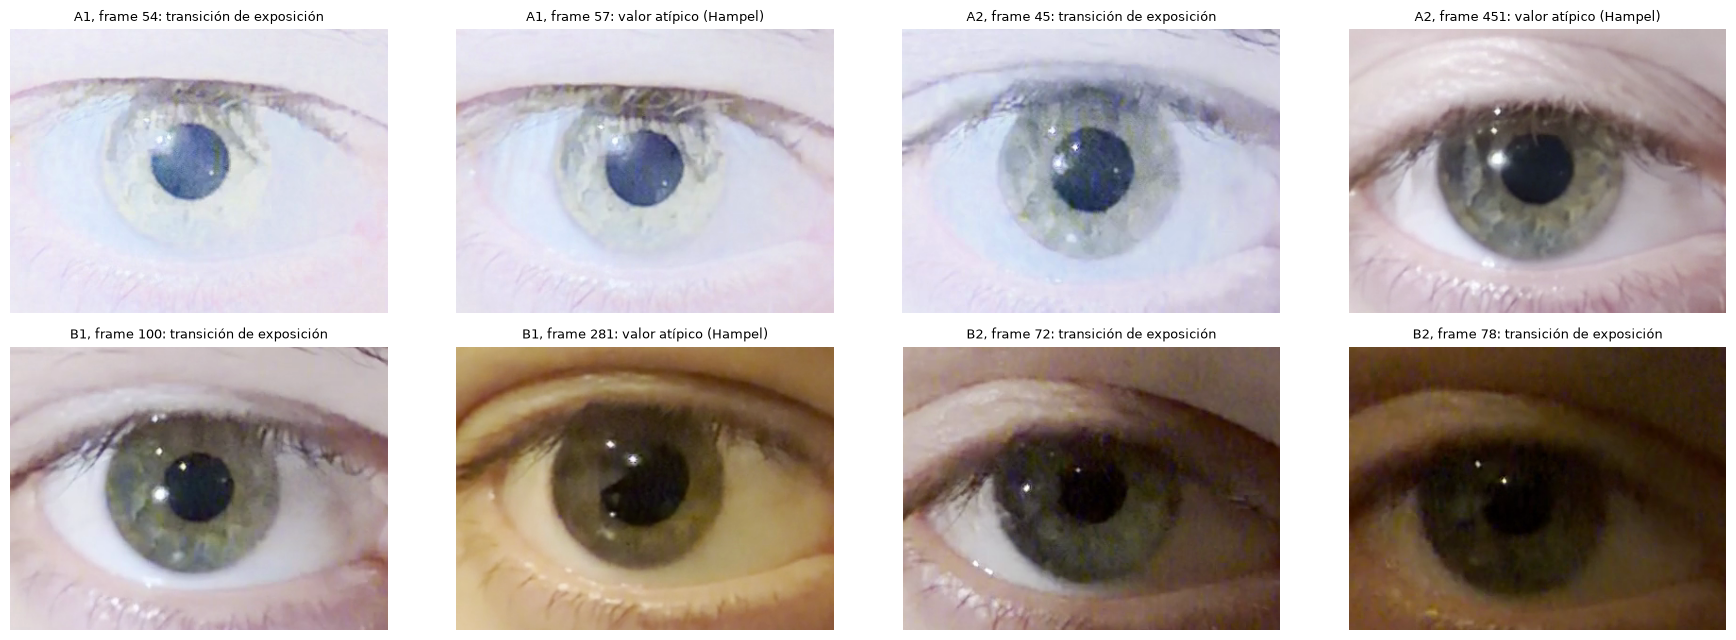

,A1,A2,B1,B2,B3,B4
transición de exposición,1,2,10,11,10,12
valor atípico (Hampel),3,45,17,1,14,20


In [ ]:
# Ejemplos de frames descartados: imagen de la ROI y motivo
def motivo(df_v, i):
    fila = df_v.loc[i]
    if np.isnan(fila["diametro_px"]):
        return "sin pupila detectada"
    if fila["ajuste_rayos"] < 0.6:
        return "ajuste de círculo pobre"
    salto = abs(df_v["brillo"].diff().loc[i]) if i > 0 else 0
    if salto > 12 or fila["brillo"] < 0.6 * df_v["brillo"].median():
        return "transición de exposición"
    return "valor atípico (Hampel)"

ejemplos = []
for nombre, df_v in curvas.items():
    malos = df_v.index[df_v["valido"] == 0]
    for i in malos[:: max(len(malos) // 2, 1)][:2]:
        ejemplos.append((nombre, i))
ejemplos = ejemplos[:8]

fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for ax, (nombre, i) in zip(axes.flat, ejemplos):
    df_v = curvas[nombre]
    f = leer_frame_exacto(DATA_DIR / f"{nombre}.mp4", int(i))
    cx, cy = df_v.loc[:i, "cx"].dropna().iloc[-1], df_v.loc[:i, "cy"].dropna().iloc[-1]
    roi_bgr, _, _ = recortar_roi(f, cx, cy)
    ax.imshow(cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{nombre}, frame {i}: {motivo(df_v, i)}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(ejemplos):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

conteo = pd.DataFrame({n: pd.Series([motivo(d, i) for i in d.index[d["valido"] == 0]]).value_counts()
                       for n, d in curvas.items()}).fillna(0).astype(int)
display(conteo)

Entre 0,4 y 5,0 % de los frames de cada registro se descartaron como artefactos. En los registros B, de 10 a 12 frames por video corresponden a la **transición de exposición** de la cámara al apagar la luz (en A son 1 o 2 frames, porque al encender la luz la cámara se ajusta más rápido). El resto son **valores atípicos** detectados por el filtro de Hampel: parpadeos y cierres parciales del párpado, movimientos del ojo y frames en los que el borde quedó mal definido. A2 es el registro con más descartes (45 frames), repartidos a lo largo del registro, sobre todo entre los 6 y 11 s y entre los 25 y 28 s, en tramos donde el ojo se mueve y el párpado cubre parte de la pupila. En B4, la mayoría de los descartes se concentra después de los 26 s, probablemente por movimientos del ojo o del párpado al final de la grabación.

Ningún frame quedó descartado por "sin pupila detectada" o "ajuste pobre": incluso en los parpadeos el método encuentra algún círculo, pero su diámetro se aparta tanto de los frames vecinos que el filtro de Hampel lo elimina. Por eso el filtro de Hampel es la parte más importante de la limpieza.

## Conclusiones del módulo

- Los descriptores de forma muestran una pupila regular y prácticamente circular (circularidad 0,91, excentricidad 0,32). En la textura, el iris tiene más variabilidad que la pupila, pero ningún canal de color aporta una riqueza textural claramente mayor; la textura cambia más según la zona del iris que según el canal.
- Para procesar el video completo fue necesario reemplazar los umbrales fijos del watershed por un método adaptativo (umbral por frame, rayos y ajuste robusto de un círculo), que mide el diámetro con un error de 1 a 2 px frente a la anotación manual y se mantiene estable cuando la cámara cambia la exposición.
- La curva temporal reproduce el comportamiento esperado del reflejo fotomotor: una constricción rápida y reproducible (30 a 33 % del diámetro, latencia de unos 0,47 s) seguida de un escape pupilar, y una redilatación mucho más lenta que no se completa en 30 s.
- Las principales fuentes de error son la exposición automática de la cámara (que conviene fijar al grabar), el párpado superior y los parpadeos. El pipeline las maneja automáticamente y reporta qué porcentaje de frames descartó, que sirve como indicador de la calidad de cada registro.